###**Group:**
1. Suha Khalil
2. Sandra Igboabuchukwu
3. Noelle Haviland

##**Large Project 1**
##**Title:** Scalable Diabetes Risk Analytics & Classification using PySpark

###**Project Overview and Problem Statement:**
This project aims to analyze CDC public health survey data to identify key predictors of diabetes using a PySpark Standalone cluster in the Google Colab environment. Statistical analysis will be performed to determine the correlation of features with diabetes diagnosis. Using distributed computing, we will evaluate the performance of PySpark DataFrames and MLlib in preprocessing data, performing statistical analysis and training a classification model with 1, 2, and 4 executors to analyze speedup.

In [ ]:
!pip install pyspark

In [ ]:
#Import Libraries
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import NumericType
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.stat import Correlation
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import time
import os
import psutil
import builtins

In [ ]:
#Create the Spark Session
spark = SparkSession.builder \
    .appName("DiabetesPreprocessing") \
    .getOrCreate()


In [ ]:
# load the data from github

github_url = "https://raw.githubusercontent.com/sykhalil/Big_Data_Analytics_SAT5165_Projects/refs/heads/main/Large_Project_1/diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

file_path = "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

urllib.request.urlretrieve(github_url, file_path)

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)
df.show(10)

+---------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|Diabetes_binary|HighBP|HighChol|CholCheck| BMI|Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex| Age|Education|Income|
+---------------+------+--------+---------+----+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+----+---------+------+
|            0.0|   1.0|     0.0|      1.0|26.0|   0.0|   0.0|                 0.0|         1.0|   0.0|    1.0|              0.0|          1.0|        0.0|    3.0|     5.0|    30.0|     0.0|1.0| 4.0|      6.0|   8.0|
|            0.0|   1.0|     1.0|      1.0|26.0|   1.0|   1.0|                 0.0|         0.0|   1.0|    0.0|              0.0|   

### **Data Preprocessing Workflow**

1. Load CSV  
2. Validate schema and dimensions    
3. Check missing values    
4. Inspect duplicate rows    
5. Validate variable domains and ranges  
6. Define target label and predictor features   
7. Split data into training and test sets    
8. Assemble features using 'VectorAssembler'   
9. Scale features using 'StandardScaler'

In [ ]:
df.printSchema()

root
 |-- Diabetes_binary: double (nullable = true)
 |-- HighBP: double (nullable = true)
 |-- HighChol: double (nullable = true)
 |-- CholCheck: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Smoker: double (nullable = true)
 |-- Stroke: double (nullable = true)
 |-- HeartDiseaseorAttack: double (nullable = true)
 |-- PhysActivity: double (nullable = true)
 |-- Fruits: double (nullable = true)
 |-- Veggies: double (nullable = true)
 |-- HvyAlcoholConsump: double (nullable = true)
 |-- AnyHealthcare: double (nullable = true)
 |-- NoDocbcCost: double (nullable = true)
 |-- GenHlth: double (nullable = true)
 |-- MentHlth: double (nullable = true)
 |-- PhysHlth: double (nullable = true)
 |-- DiffWalk: double (nullable = true)
 |-- Sex: double (nullable = true)
 |-- Age: double (nullable = true)
 |-- Education: double (nullable = true)
 |-- Income: double (nullable = true)



In [ ]:
#Verify the dataset's dimensions
print("Number of rows:", df.count())
print("Number of columns:", len(df.columns))

Number of rows: 70692
Number of columns: 22


In [ ]:
#Check Missing Values
null_counts = df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

null_counts.show()

+---------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|Diabetes_binary|HighBP|HighChol|CholCheck|BMI|Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age|Education|Income|
+---------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|              0|     0|       0|        0|  0|     0|     0|                   0|           0|     0|      0|                0|            0|          0|      0|       0|       0|       0|  0|  0|        0|     0|
+---------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+------------

***No missing values were found, no imputation or row removal needed!***

In [ ]:
# Check Duplicates
total_rows = df.count()
distinct_rows = df.distinct().count()

duplicate_rows = total_rows - distinct_rows

print("Total rows:", total_rows)
print("Distinct rows:", distinct_rows)
print("Exact duplicate rows:", duplicate_rows)

Total rows: 70692
Distinct rows: 69057
Exact duplicate rows: 1635


***Duplicate rows were inspected, but exact duplicate rows does not necessarily mean they are accedintal, we are using a balanced derivative dataset, records may have been selected or resampled to create equal class sizes; therefore, duplicates will not be removed.***

In [ ]:
#Confirm the class balance
df.groupBy("Diabetes_binary").count().show()


+---------------+-----+
|Diabetes_binary|count|
+---------------+-----+
|            0.0|35346|
|            1.0|35346|
+---------------+-----+



In [ ]:
#In percentage:
total_rows = df.count()

df.groupBy("Diabetes_binary") \
  .count() \
  .withColumn(
      "Percentage",
      round(col("count") / total_rows * 100, 2)
  ) \
  .show()

+---------------+-----+----------+
|Diabetes_binary|count|Percentage|
+---------------+-----+----------+
|            0.0|35346|      50.0|
|            1.0|35346|      50.0|
+---------------+-----+----------+



In [ ]:
# Range Validation for numeric columns
df.select(
    min("BMI").alias("BMI_min"),
    max("BMI").alias("BMI_max"),
    min("Age").alias("Age_min"),
    max("Age").alias("Age_max"),
    min("GenHlth").alias("GenHlth_min"),
    max("GenHlth").alias("GenHlth_max"),
    min("MentHlth").alias("MentHlth_min"),
    max("MentHlth").alias("MentHlth_max"),
    min("PhysHlth").alias("PhysHlth_min"),
    max("PhysHlth").alias("PhysHlth_max"),
    min("Education").alias("Education_min"),
    max("Education").alias("Education_max"),
    min("Income").alias("Income_min"),
    max("Income").alias("Income_max")
).show()

+-------+-------+-------+-------+-----------+-----------+------------+------------+------------+------------+-------------+-------------+----------+----------+
|BMI_min|BMI_max|Age_min|Age_max|GenHlth_min|GenHlth_max|MentHlth_min|MentHlth_max|PhysHlth_min|PhysHlth_max|Education_min|Education_max|Income_min|Income_max|
+-------+-------+-------+-------+-----------+-----------+------------+------------+------------+------------+-------------+-------------+----------+----------+
|   12.0|   98.0|    1.0|   13.0|        1.0|        5.0|         0.0|        30.0|         0.0|        30.0|          1.0|          6.0|       1.0|       8.0|
+-------+-------+-------+-------+-----------+-----------+------------+------------+------------+------------+-------------+-------------+----------+----------+



In [ ]:
#Check Binary Columns
binary_cols = [
    "Diabetes_binary",
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]

for c in binary_cols:
    values = [row[c] for row in df.select(c).distinct().orderBy(c).collect()]
    print(c, values)

Diabetes_binary [0.0, 1.0]
HighBP [0.0, 1.0]
HighChol [0.0, 1.0]
CholCheck [0.0, 1.0]
Smoker [0.0, 1.0]
Stroke [0.0, 1.0]
HeartDiseaseorAttack [0.0, 1.0]
PhysActivity [0.0, 1.0]
Fruits [0.0, 1.0]
Veggies [0.0, 1.0]
HvyAlcoholConsump [0.0, 1.0]
AnyHealthcare [0.0, 1.0]
NoDocbcCost [0.0, 1.0]
DiffWalk [0.0, 1.0]
Sex [0.0, 1.0]


In [ ]:
#Define Predictor Columns and Target Column
label_col = "Diabetes_binary"

feature_cols = [
    c for c in df.columns
    if c != label_col
]

print("Target column:", label_col)
print("Number of predictor columns:", len(feature_cols))
print("Predictor columns:")
print(feature_cols)

Target column: Diabetes_binary
Number of predictor columns: 21
Predictor columns:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [ ]:
# Validated dataset, To be used in statistical analysis
validated_df = df

In [ ]:
#Split the data
train_df, test_df = df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_df.count())
print("Test rows:", test_df.count())

Training rows: 56487
Test rows: 14205


In [ ]:
#Create the feature vector with VectorAssembler for both training and test sets:
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

train_assembled = assembler.transform(train_df)
test_assembled = assembler.transform(test_df)

In [ ]:
#Fit the StandardScaler to Training Data
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withStd=True,
    withMean=False
)

scaler_model = scaler.fit(train_assembled)

In [ ]:
#Apply Scaler to both train and test data
train_scaled = scaler_model.transform(train_assembled)
test_scaled = scaler_model.transform(test_assembled)

In [ ]:
# Inspect the scaled feature vector with the target column for the training set
train_scaled.select(
    "Diabetes_binary",
    "scaledFeatures"
).show(5, truncate=False)

+---------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|Diabetes_binary|scaledFeatures                                                                                                                                                                                                                                  |
+---------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|0.0            |(21,[3,4,6,8,9,12,13,15,18,19,20],[2.104186696183848,2.0024456525672694,2.8166508000931048,2.0533176933340584,2.452112027159481,3.4248395312299493,2.696961504423741,2.886015791643497,2.4541211690879257,4.86

In [ ]:
#Final Verification
print("Training rows:", train_scaled.count())
print("Test rows:", test_scaled.count())

print("Training partitions:", train_scaled.rdd.getNumPartitions())
print("Test partitions:", test_scaled.rdd.getNumPartitions())

Training rows: 56487
Test rows: 14205
Training partitions: 2
Test partitions: 2


### **Statistical Correlation Analysis Workflow**

1. Use the validated dataset prepared during preprocessing  
2. Use the defined predictor variables and 'Diabetes_binary' target  
3. Compute Pearson correlation coefficients between each predictor and 'Diabetes_binary'  
4. Identify the strongest positive and negative associations  
5. Examine correlation among predictor variables  
6. Summarize the main statistical findings

DESCRIPTIVE STATISTICS

In [ ]:
from pyspark.sql import functions as F

# Descriptive statistics using PySpark
validated_df = df

descriptive_stats = validated_df.describe()

# Format numerical results to 2 decimal places
descriptive_stats = descriptive_stats.select(
    "summary",
    *[
        F.format_number(F.col(c).cast("double"), 2).alias(c)
        for c in descriptive_stats.columns
        if c != "summary"
    ]
)

# Display results
descriptive_stats.show(truncate=False)

+-------+---------------+---------+---------+---------+---------+---------+---------+--------------------+------------+---------+---------+-----------------+-------------+-----------+---------+---------+---------+---------+---------+---------+---------+---------+
|summary|Diabetes_binary|HighBP   |HighChol |CholCheck|BMI      |Smoker   |Stroke   |HeartDiseaseorAttack|PhysActivity|Fruits   |Veggies  |HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth  |MentHlth |PhysHlth |DiffWalk |Sex      |Age      |Education|Income   |
+-------+---------------+---------+---------+---------+---------+---------+---------+--------------------+------------+---------+---------+-----------------+-------------+-----------+---------+---------+---------+---------+---------+---------+---------+---------+
|count  |70,692.00      |70,692.00|70,692.00|70,692.00|70,692.00|70,692.00|70,692.00|70,692.00           |70,692.00   |70,692.00|70,692.00|70,692.00        |70,692.00    |70,692.00  |70,692.00|70,692.00|70,69

### Descriptive Statistical Analysis

Descriptive statistics were computed to summarize the characteristics of the 70,692 observations in the Diabetes Health Indicators BRFSS 2015 dataset. The outcome variable was evenly distributed, with 50% of observations classified as diabetes and 50% as no diabetes, reflecting the balanced sampling design.

Approximately 56.35% of respondents reported high blood pressure, 52.57% reported high cholesterol, and 97.53% reported having undergone cholesterol screening. The average body mass index (BMI) was approximately 29.86, with a standard deviation of 7.11 and values ranging from 12 to 98.

analysis showed that approximately 47.53% of respondents reported a history of smoking, while 6.22% reported having experienced a stroke. Furthermore, 14.78% reported a history of coronary heart disease or heart attack.

Regarding lifestyle indicators, approximately 70.30% of respondents reported engaging in physical activity during the previous 30 days, while 61.18% reported consuming fruit at least once daily.

These findings provide an overview of the respondents' health characteristics,  conditions and lifestyle characteristics, forming a foundation for subsequent analyses of their associations with diabetes status.


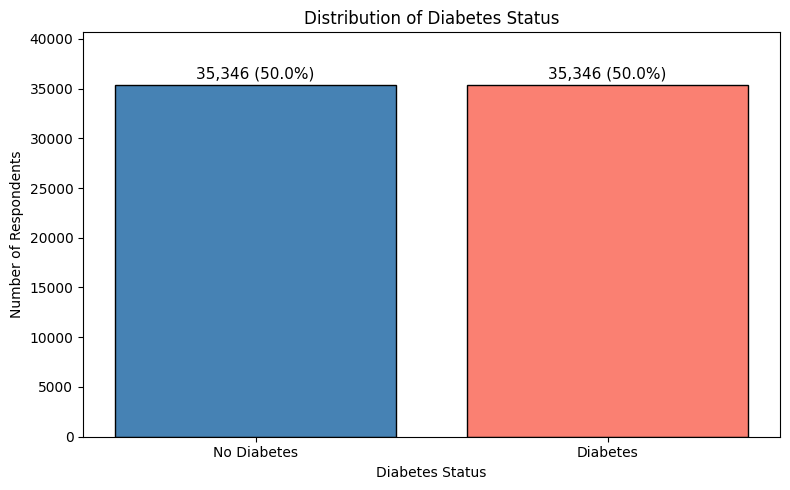

In [ ]:
# Calculate frequency and percentage of diabetes status
total_rows = validated_df.count()
diabetes_frequency = (
    validated_df
    .groupBy("Diabetes_binary")
    .agg(F.count("*").alias("Frequency"))
    .withColumn(
        "Percentage",
        F.round(F.col("Frequency") / total_rows * 100, 2)
    )
    .orderBy("Diabetes_binary")
)

# Collect the summarized PySpark results
target_data = (
    diabetes_frequency
    .orderBy("Diabetes_binary")
    .collect()
)

# Extract frequency and percentage
frequencies = [row["Frequency"] for row in target_data]
percentages = [row["Percentage"] for row in target_data]

# Create labels based on diabetes status
labels = [
    "No Diabetes" if row["Diabetes_binary"] == 0
    else "Diabetes"
    for row in target_data
]

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    frequencies,
    color=["steelblue", "salmon"],
    edgecolor="black"
)

# Display frequency and percentage above each bar using native Python built-in max
for bar, freq, pct in zip(
    bars,
    frequencies,
    percentages
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + builtins.max(frequencies) * 0.02,
        f"{freq:,} ({pct:.1f}%)",
        ha="center",
        fontsize=11
    )

plt.xlabel("Diabetes Status")
plt.ylabel("Number of Respondents")
plt.title("Distribution of Diabetes Status")

plt.ylim(0, builtins.max(frequencies) * 1.15)

plt.tight_layout()
plt.show()

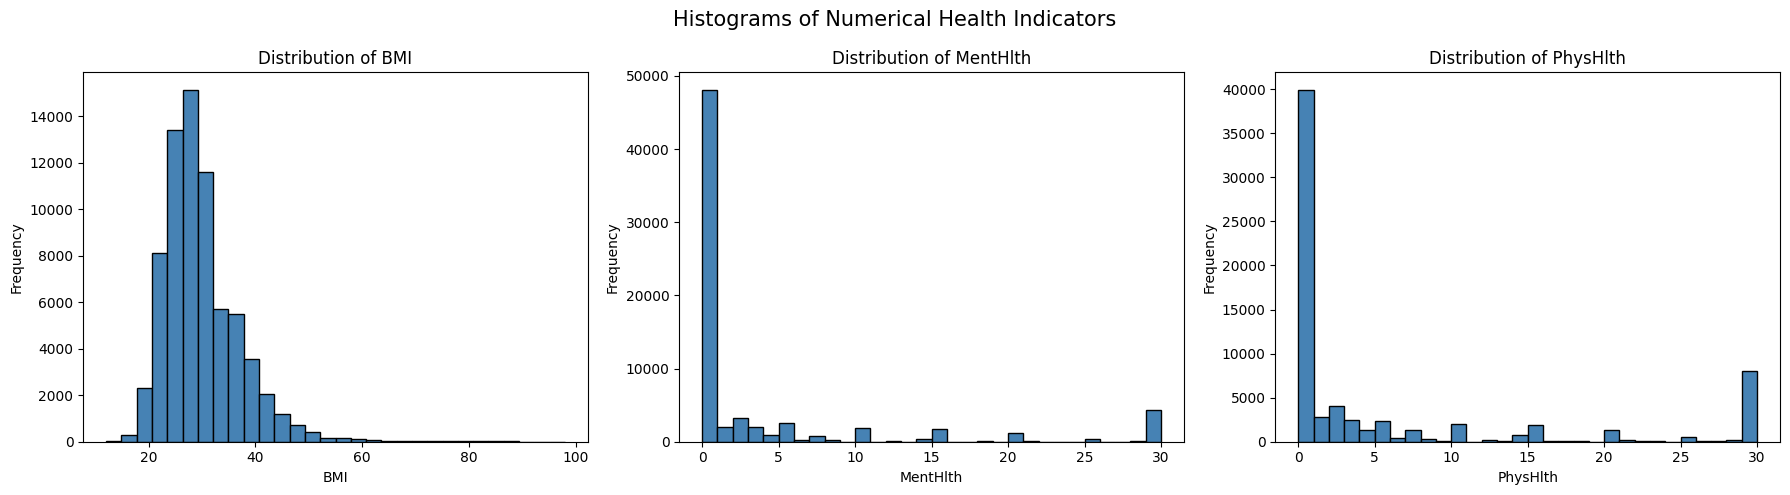

In [ ]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Select numerical variables
numerical_columns = ["BMI", "MentHlth", "PhysHlth"]

# Create histograms
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, numerical_columns):

    # Select numerical column and remove missing values
    numeric_df = validated_df.select(
        F.col(col).cast("double").alias(col)
    ).where(
        F.col(col).isNotNull() &
        ~F.isnan(F.col(col))
    )

    # Calculate minimum and maximum using PySpark
    stats = numeric_df.agg(
        F.min(col).alias("minimum"),
        F.max(col).alias("maximum")
    ).first()

    min_val = stats["minimum"]
    max_val = stats["maximum"]

    if min_val is None:
        ax.set_title(f"Distribution of {col} (No Data)")
        continue

    # Define 30 histogram bins
    bins = 30

    if min_val == max_val:
        min_val -= 0.5
        max_val += 0.5

    bin_width = (max_val - min_val) / bins

    # Assign observations to histogram bins using PySpark
    binned_df = numeric_df.withColumn(
        "bin",
        F.least(
            F.floor(
                (F.col(col) - F.lit(min_val)) /
                F.lit(bin_width)
            ),
            F.lit(bins - 1)
        ).cast("int")
    )

    # Calculate frequency per bin using PySpark
    frequency_df = binned_df.groupBy("bin").count()

    # Collect only aggregated frequencies
    frequency_data = frequency_df.collect()

    frequency_dict = {
        row["bin"]: row["count"]
        for row in frequency_data
    }

    frequencies = [
        frequency_dict.get(i, 0)
        for i in range(bins)
    ]

    bin_edges = [
        min_val + i * bin_width
        for i in range(bins + 1)
    ]

    # Plot histogram using Matplotlib
    ax.bar(
        bin_edges[:-1],
        frequencies,
        width=bin_width,
        align="edge",
        color="steelblue",
        edgecolor="black"
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Histograms of Numerical Health Indicators",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Histogram Analysis of Numerical Health Indicators

Histograms were used to examine the distributions of three numerical health indicators: Body Mass Index (BMI), poor mental health days (MentHlth), and poor physical health days (PhysHlth).

The BMI distribution was positively skewed, with most respondents having BMI values concentrated around 25–30 and a smaller number recording substantially higher values.

The distributions of poor mental health days and poor physical health days were strongly right-skewed, with a large proportion of respondents reporting zero days of poor health. Both variables also showed noticeable concentrations at 30 days, indicating that some respondents reported experiencing poor health throughout the entire previous month.

Overall, the histograms revealed non-symmetric distributions among the numerical health indicators, particularly the mental and physical health variables.

CORRELATION ANALYSIS


In [ ]:
# 1. Select all numerical variables using PySpark
numerical_columns = [
    field.name
    for field in validated_df.schema.fields
    if isinstance(field.dataType, NumericType)
]

# 2. Remove rows with missing values
correlation_df = validated_df.select(
    *numerical_columns
).dropna()

# 3. Combine numerical variables into a feature vector
assembler = VectorAssembler(
    inputCols=numerical_columns,
    outputCol="features"
)

vector_df = assembler.transform(correlation_df)

# 4. Calculate Pearson correlation matrix using PySpark
correlation_matrix = Correlation.corr(
    vector_df,
    "features",
    "pearson"
).head()[0].toArray()

# 5. Create a labeled correlation matrix
correlation_table = pd.DataFrame(
    correlation_matrix,
    index=numerical_columns,
    columns=numerical_columns
)

# 6. Extract correlations with diabetes
diabetes_correlation = (
    correlation_table[["Diabetes_binary"]]
    .drop(index="Diabetes_binary")
    .rename(columns={
        "Diabetes_binary": "Pearson Correlation (r)"
    })
)

# 7. Sort features by absolute correlation strength
# Without displaying an absolute correlation column
diabetes_correlation = diabetes_correlation.reindex(
    diabetes_correlation["Pearson Correlation (r)"]
    .abs()
    .sort_values(ascending=False)
    .index
)

# 8. Identify the five strongest features
strongest_features = diabetes_correlation.head(5).index

# 9. Highlight strongest features
def highlight_strongest(row):
    if row.name in strongest_features:
        return ["background-color: #fff2b3"] * len(row)
    return [""] * len(row)

# 10. Display the complete correlation table
print("PEARSON CORRELATION OF HEALTH INDICATORS WITH DIABETES")

display(
    diabetes_correlation.style
    .format("{:+.3f}")
    .apply(highlight_strongest, axis=1)
    .set_caption(
        "Health Indicators Ranked by Pearson Correlation with Diabetes"
    )
)

PEARSON CORRELATION OF HEALTH INDICATORS WITH DIABETES


,Pearson Correlation (r)
GenHlth,+0.408
HighBP,+0.382
BMI,+0.293
HighChol,+0.289
Age,+0.279
DiffWalk,+0.273
Income,-0.224
PhysHlth,+0.213
HeartDiseaseorAttack,+0.212
Education,-0.170


CORRELATION MATRIX


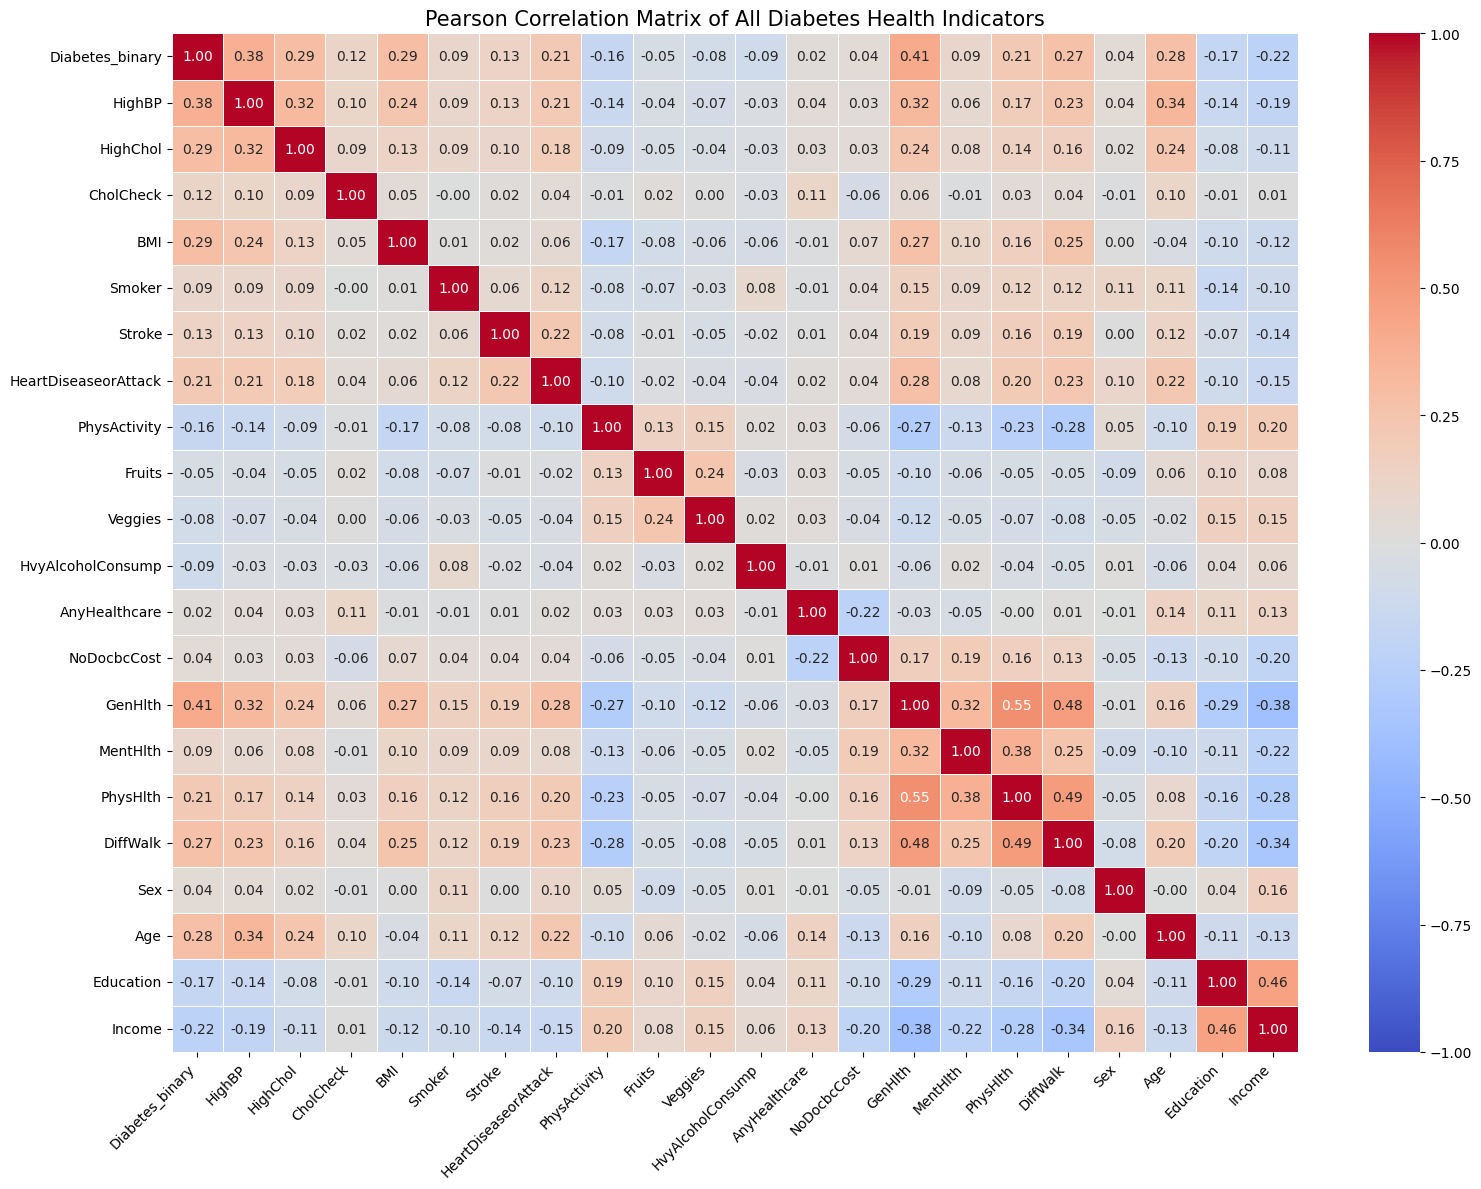

In [ ]:
# Create a labeled correlation matrix for all features
correlation_table = pd.DataFrame(
    correlation_matrix,
    index=numerical_columns,
    columns=numerical_columns
)

# Create Pearson correlation heatmap for all features
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_table,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Pearson Correlation Matrix of All Diabetes Health Indicators",
    fontsize=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Correlation Analysis

The correlation analysis revealed that general health (r = 0.41) had the strongest positive correlation with diabetes status, while income (r = −0.22) had the strongest negative correlation. Among the predictors, general health and physical health demonstrated the strongest positive correlation (r = 0.55), whereas general health and income exhibited the strongest negative correlation (r = −0.38). These findings suggest that poorer general health is associated with diabetes status and more days of poor physical health, while higher income is associated with better reported general health.

Overall, the findings indicate that diabetes status is associated with multiple health and demographic characteristics. However, correlation does not establish causation, and multivariable logistic regression was used to examine adjusted associations.

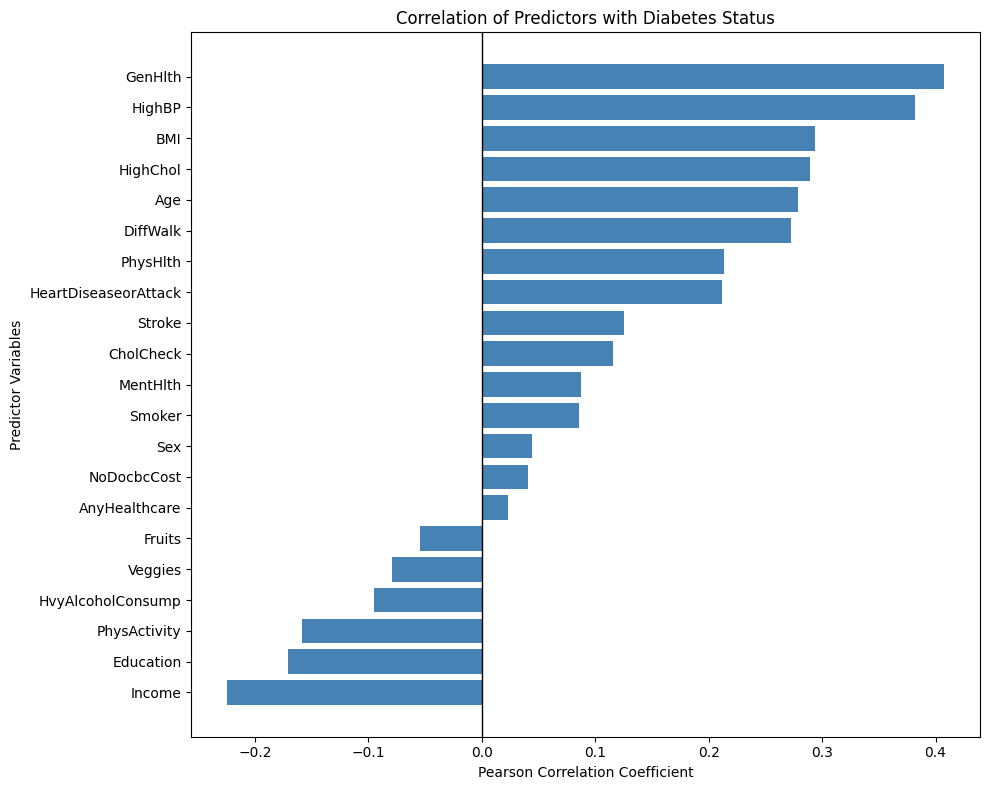

In [ ]:
# Identify the position of the diabetes target
target_index = numerical_columns.index("Diabetes_binary")

# Extract correlations with diabetes
target_correlations = [
    (column, float(correlation_matrix[i, target_index]))
    for i, column in enumerate(numerical_columns)
    if column != "Diabetes_binary"
]

# Sort correlations from lowest to highest
target_correlations = sorted(
    target_correlations,
    key=lambda x: x[1]
)

# Extract predictor names and correlation values
predictors = [
    item[0] for item in target_correlations
]

correlation_values = [
    item[1] for item in target_correlations
]

# Create horizontal bar chart
plt.figure(figsize=(10, 8))

plt.barh(
    predictors,
    correlation_values,
    color="steelblue"
)

plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Predictor Variables")
plt.title("Correlation of Predictors with Diabetes Status")

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.tight_layout()
plt.show()

### **Binary Classification Workflow**

1. Use the preprocessed 'train_scaled' and 'test_scaled' datasets
2. Create a Spark MLlib Logistic Regression model
3. Use the model and 'scaledFeatures' to predict 'Diabetes_binary'
4. Generate predictions on the test dataset
5. Evaluate classification performance
6. Report model metrics and summarize the results

In [ ]:
# Tune Logistic Regression model parameters
lr = LogisticRegression(
    family = "binomial",
    featuresCol = "scaledFeatures",
    labelCol = "Diabetes_binary")

# Build parameter grid
paramGrid = (ParamGridBuilder()
            .addGrid(lr.maxIter, [5, 10, 15, 20])
            .addGrid(lr.regParam, [0.1, 0.05, 0.01])
            .addGrid(lr.elasticNetParam, [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
            .build())

# Choose area under ROC curve as evaluation metric for hyperparameter tuning
evaluator = BinaryClassificationEvaluator(metricName = "areaUnderROC", labelCol = "Diabetes_binary")

# Use K-fold cv for model selection
cv = CrossValidator(
    estimator = lr,
    estimatorParamMaps = paramGrid,
    evaluator = evaluator,
    numFolds = 5
)

# Fit the grid on the training data
lrModel = cv.fit(train_scaled)

# Make predictions on the test data using the best model
predictions = lrModel.bestModel.transform(test_scaled)

I fit a binary logistic regression model (using five-fold cross-validation for hyperparameter tuning) on the training data. I tuned the parameters for maximum iterations, regularization and elastic net (which determines whether L2 or L1 regularization is prioritized). For model tuning, I used area under the ROC curve as the main metric.

In [ ]:
# Print best model hyperparameters
print("Elastic net parameter:", lrModel.bestModel._java_obj.getElasticNetParam())
print("Regularization parameter:", lrModel.bestModel._java_obj.getRegParam())
print("Iterations parameter:", lrModel.bestModel._java_obj.getMaxIter())

Elastic net parameter: 0.1
Regularization parameter: 0.01
Iterations parameter: 20


In [ ]:
# Training set confusion matrix
trainPredictions = lrModel.bestModel.transform(train_scaled)
trainPredictionsAndLabels = trainPredictions.select(
    "prediction", "Diabetes_binary"
).rdd.map(lambda row: (float(row["prediction"]), float(row["Diabetes_binary"])))

train_metrics = MulticlassMetrics(trainPredictionsAndLabels)

train_cm = train_metrics.confusionMatrix().toArray()
train_confusion = pd.DataFrame(
    train_cm,
    index = ["Actual Negative", "Actual Positive"],
    columns = ["Predicted Negative", "Predicted Positive"]
)

print(train_confusion)

/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


                 Predicted Negative  Predicted Positive
Actual Negative             20612.0              7673.0
Actual Positive              6555.0             21647.0


From the training-data confusion matrix, we see that there are a lower number of false negatives than false positives. In healthcare, this is what we want, because it is much more harmful to miss someone that has diabetes and not start treating them than to falsely diagnose someone with diabetes. In a perfect world, we do not want either, but we prefer fewer false negatives, and that is what we observe here on the training data.

In [ ]:
# Other metrics
train_tp = train_cm[1,1]
train_tn = train_cm[0,0]
train_fp = train_cm[0,1]
train_fn = train_cm[1,0]

train_accuracy = (train_tp + train_tn)/(train_tp + train_tn + train_fp + train_fn)
train_precision = (train_tp)/(train_tp + train_fp)
train_recall = (train_tp)/(train_tp + train_fn)

print("Training Accuracy:", train_accuracy)
print("Training Precision:", train_precision)
print("Training Recall:", train_recall)

Training Accuracy: 0.7481190362384266
Training Precision: 0.7383015006821282
Training Recall: 0.76756967590951


The model accuracy is 0.75, which is higher than chance, but not very good. The recall (0.77) is higher than the precision (0.74), suggesting that there are fewer false negatives.

In [ ]:
# Training set ROC curve
training_summary = lrModel.bestModel.summary
training_summary.areaUnderROC

0.8246727399344597

The area under the ROC curve is 0.824, which means that our classifier is good, but has room for improvement. It makes sense that this is the highest metric because it is the one we optimized during the training process.

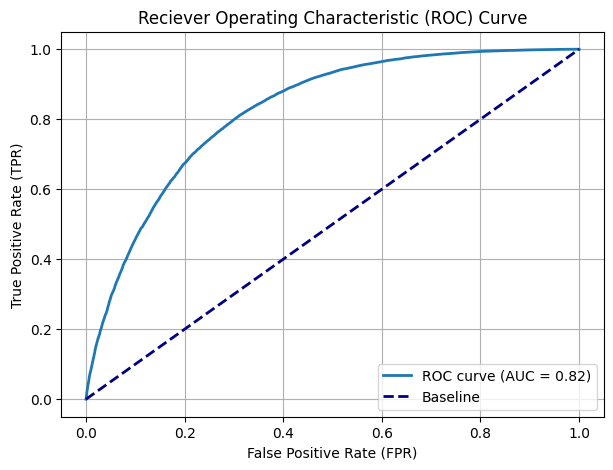

In [ ]:
# Plot of ROC curve
roc_df = training_summary.roc.toPandas()

plt.figure(figsize = (7,5))
plt.plot(roc_df["FPR"], roc_df["TPR"], lw = 2, label = f"ROC curve (AUC = {training_summary.areaUnderROC:.2f})")
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label = "Baseline")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Reciever Operating Characteristic (ROC) Curve")
plt.legend(loc = "lower right")
plt.grid(True)
plt.show()

From this plot, we see that the model (solid blue line) performs significantly better on the training set than chance (the dotted blue line).

In [ ]:
# Test AUC
test_summary = evaluator.evaluate(predictions)
print(test_summary)


0.8251234086641872


The test area under the ROC curve is 0.825. This is surprisingly higher than this metric on the training set, though not by very much. Similar training and test performance like what we observe here suggests that the model generalizes well to unseen data.

In [ ]:
# Test confusion matrix
testPredictionsAndLabels = predictions.select(
    "prediction", "Diabetes_binary"
).rdd.map(lambda row: (float(row["prediction"]), float(row["Diabetes_binary"])))

test_metrics = MulticlassMetrics(testPredictionsAndLabels)

test_cm = test_metrics.confusionMatrix().toArray()
test_confusion = pd.DataFrame(
    test_cm,
    index = ["Actual Negative", "Actual Positive"],
    columns = ["Predicted Negative", "Predicted Positive"]
)

print(test_confusion)

/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


                 Predicted Negative  Predicted Positive
Actual Negative              5132.0              1929.0
Actual Positive              1653.0              5491.0


Once again, we observe that there are fewer false negatives than false positives. This again suggests good test-set generalization, as well as that the model has higher recall.

In [ ]:
# Other metrics
test_tp = test_cm[1,1]
test_tn = test_cm[0,0]
test_fp = test_cm[0,1]
test_fn = test_cm[1,0]

test_accuracy = (test_tp + test_tn)/(test_tp + test_tn + test_fp + test_fn)
test_precision = (test_tp)/(test_tp + test_fp)
test_recall = (test_tp)/(test_tp + test_fn)

print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)

Test Accuracy: 0.7478352692713833
Test Precision: 0.7400269541778975
Test Recall: 0.7686170212765957


Of these three metrics, recall (0.768) is the highest, which once again is preferred for models attempting to predict a future diagnosis in the medical field.

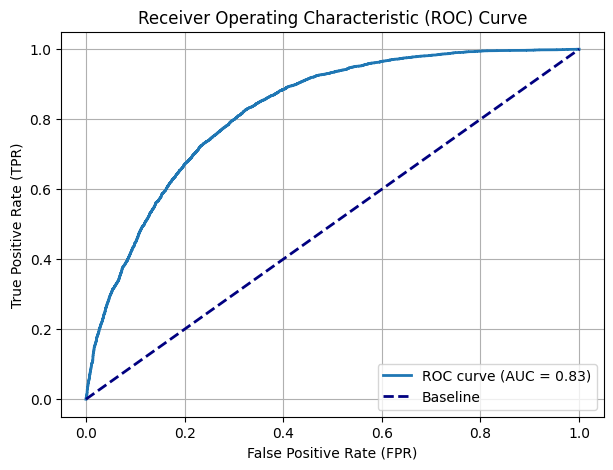

In [ ]:
# ROC curve
testScoresAndLabels = predictions.select(
    vector_to_array("probability")[1].alias("score"),
    "Diabetes_binary"
).rdd.map(
    lambda row: (float(row["score"]), float(row["Diabetes_binary"]))
)
metrics = testScoresAndLabels.collect()
metrics.sort(key = lambda x: x[0], reverse = True)

total_positive = builtins.sum(1 for x in metrics if float(x[1]) == 1.0)
total_negative = len(metrics) - total_positive
tp = 0
fp = 0
fpr = [0.0]
tpr = [0.0]
i = 0

while i < len(metrics):
  threshold = metrics[i][0]
  while i < len(metrics) and metrics[i][0] == threshold:
    if metrics[i][1] == 1.0:
      tp += 1
    else:
      fp += 1
    i += 1
  tpr.append(tp/total_positive)
  fpr.append(fp/total_negative)

plt.figure(figsize = (7,5))
plt.plot(fpr, tpr, lw = 2, label = f"ROC curve (AUC = {test_summary:.2f})")
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label = "Baseline")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

The ROC curve (solid blue) has significantly higher performance than chance (dotted blue), and has slightly higher performance than on the training set. This is slightly exaggerated by this plot, because the true difference is 0.01 and not 0.1, but is stil promising for the model's ability to generalize.

### **Performance Scaling Experiment**

Each team member will run and time their complete assigned Spark workload using:

**1** executor with 1 core

**2** executors with 1 core each

**4** executors with 1 core each

Each configuration will be repeated at least 3 times.

For each run, we will record:
- Wall-clock runtime
- Number of executors
- Number of partitions
- CPU count
- Available RAM

The mean runtime and standard deviation will be calculated for each configuration.

Speedup will be calculated as:

**Speedup = $T_1 / T_n$**

where $T_1$ is the mean runtime with 1 executor and $T_n$ is the mean runtime with n executors.

### **Team Performance Comparison**

The preprocessing, correlation analysis, and logistic regression workloads will be compared to determine which method scales better as the number of executors increases.

In [ ]:
import pandas as pd
total_team_results_df = pd.DataFrame({
  "Section": ["Preprocessing", "Preprocessing", "Preprocessing", "Preprocessing",
              "Preprocessing", "Preprocessing", "Preprocessing", "Preprocessing",
              "Preprocessing", "Correlation Analysis", "Correlation Analysis",
              "Correlation Analysis", "Correlation Analysis", "Correlation Analysis",
              "Correlation Analysis", "Correlation Analysis", "Correlation Analysis",
              "Correlation Analysis", "Machine Learning", "Machine Learning",
              "Machine Learning", "Machine Learning", "Machine Learning",
              "Machine Learning", "Machine Learning", "Machine Learning",
              "Machine Learning"],
  "Executors": ["1", "1", "1", "2", "2", "2", "4", "4", "4", "1", "1", "1", "2",
                "2", "2", "4", "4", "4", "1", "1", "1", "2", "2", "2", "4", "4",
                "4"],
  "Run": ["1", "2", "3", "1", "2", "3", "1", "2", "3", "1", "2", "3", "1", "2",
          "3", "1", "2", "3", "1", "2", "3", "1", "2", "3", "1", "2", "3"],
  "Runtime_seconds": [15.410951, 14.742853, 15.004741	, 11.967259, 11.801533, 13.486154, 14.168899, 11.747309, 10.901110, 8.165, 7.825, 7.790, 8.855315, 7.917455, 9.317813, 15.909108, 9.946076, 8.444752,
                      470.741349, 462.574900, 459.758121, 397.389969, 394.561155,
                      398.418961, 458.963468,	473.688267, 409.634551],
  "Partitions": [8, 8, 8, 8, 8, 8, 8, 8, 8, 2, 2, 2, 2, 2, 2, 2, 2, 2, 200, 200,
                 200, 200, 200, 200, 200, 200, 200],
  "CPU_count": [20, 20, 20, 20, 20, 20, 20, 20, 20, 16, 16, 16, 16, 16, 16, 16, 16, 16, 8, 8, 8, 8,
                8, 8, 8, 8, 8],
  "Available_RAM_GB": [13.817711, 13.722424, 13.437943, 13.157116, 13.122475, 13.195122, 11.932659, 11.879982, 11.887127, 1.198, 1.131, 1.000, 0.698044, 0.660892, 0.974659, 0.858083, 1.20709, 1.721691,
                       1.426773, 1.360306, 1.384995, 1.407776, 1.409119, 1.273254,
                       1.332092, 1.248917, 1.261719],
  "Total_RAM_GB": [31.7, 31.7, 31.7, 31.7, 31.7, 31.7, 31.7, 31.7, 31.7, 15.34, 15.34, 15.34, 15.34, 15.34, 15.4, 15.34, 15.34, 15.34, 8.0, 8.0,
                   8.0, 8.0, 8.0, 8.0, 8.0, 8.0, 8.0]
})
print(total_team_results_df)

                 Section Executors Run  Runtime_seconds  Partitions  \
0          Preprocessing         1   1        15.410951           8   
1          Preprocessing         1   2        14.742853           8   
2          Preprocessing         1   3        15.004741           8   
3          Preprocessing         2   1        11.967259           8   
4          Preprocessing         2   2        11.801533           8   
5          Preprocessing         2   3        13.486154           8   
6          Preprocessing         4   1        14.168899           8   
7          Preprocessing         4   2        11.747309           8   
8          Preprocessing         4   3        10.901110           8   
9   Correlation Analysis         1   1         8.165000           2   
10  Correlation Analysis         1   2         7.825000           2   
11  Correlation Analysis         1   3         7.790000           2   
12  Correlation Analysis         2   1         8.855315           2   
13  Co

In [ ]:
average_team_results_df = pd.DataFrame({
  "Section": ["Preprocessing", "Preprocessing", "Preprocessing", "Correlation Analysis",
              "Correlation Analysis", "Correlation Analysis", "Machine Learning",
              "Machine Learning", "Machine Learning"],
  "Executors": ["1", "2", "4", "1", "2", "4", "1", "2", "4"],
  "Mean_Runtime_s": [15.052848, 12.418315, 12.272439, 7.926497, 8.696861, 11.433312, 464.358123, 396.790028, 447.428762],
  "Std_Runtime_s": [0.336637, 0.928481, 1.696005, 0.207409, 0.713499, 3.948171, 5.704625, 1.997652, 33.548573],
  "Speedup": [1.000000,1.212149 , 1.226557, 1.000000, 0.911420, 0.693281, 1.000000, 1.170287, 1.037837]
})
print(average_team_results_df)

                Section Executors  Mean_Runtime_s  Std_Runtime_s   Speedup
0         Preprocessing         1       15.052848       0.336637  1.000000
1         Preprocessing         2       12.418315       0.928481  1.212149
2         Preprocessing         4       12.272439       1.696005  1.226557
3  Correlation Analysis         1        7.926497       0.207409  1.000000
4  Correlation Analysis         2        8.696861       0.713499  0.911420
5  Correlation Analysis         4       11.433312       3.948171  0.693281
6      Machine Learning         1      464.358123       5.704625  1.000000
7      Machine Learning         2      396.790028       1.997652  1.170287
8      Machine Learning         4      447.428762      33.548573  1.037837


<Figure size 600x400 with 0 Axes>

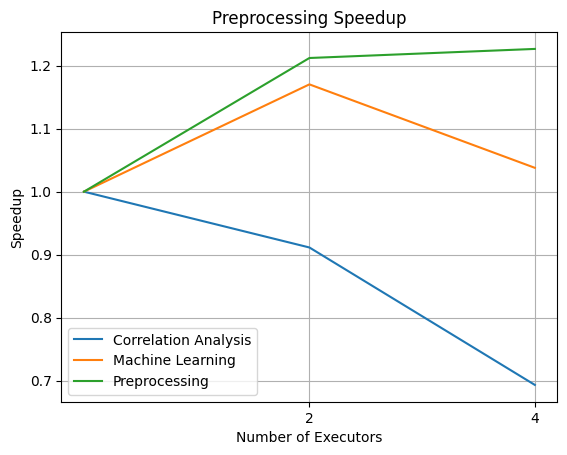

In [ ]:
# Comparison plot
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

fig, ax = plt.subplots()

for category, group in average_team_results_df.groupby("Section"):
  ax.plot(group["Executors"], group["Speedup"])


plt.xlabel("Number of Executors")
plt.ylabel("Speedup")
plt.title("Preprocessing Speedup")
plt.xticks([1, 2])
plt.grid(True)
plt.legend(["Correlation Analysis", "Machine Learning", "Preprocessing"])
plt.show()